**SAPIANS** · SCC5819 · MÓDULO 08 — INTERAÇÃO · MOLNAR, CAP. 21

# O efeito da idade depende do restante da ficha?

O ALE descrevia um efeito principal; agora medimos o desvio em relação à soma de dependências parciais.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/08-feature-interaction/notebooks/interaction_walkthrough.ipynb)

---

**Objetivos.** Executar o método no modelo fixo do curso, conferir a fórmula e delimitar o que a medida permite concluir.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Do resíduo aditivo ao H

Centralizamos $PD_j$, $PD_k$ e $PD_{jk}$ nos mesmos pares observados. Então $H^2=\sum_i(PD_{jk}-PD_j-PD_k)^2/\sum_i PD_{jk}^2$. Usamos a probabilidade de óbito; a escala é parte da pergunta. Pares são declarados antes do cálculo, sem busca pelo maior resultado.

def h_par(prever, fundo, avaliacao, par, *, tolerancia=1e-14) -> dict:
    """H² de Friedman–Popescu nas combinações observadas, com PDs centralizadas.

    O fundo integra o complemento; `avaliacao` define os pontos e sua
    ponderação empírica. Não se troca essa ponderação por uma grade cartesiana.
    Denominador quase nulo retorna NaN, não evidência de ausência de interação.
    H não é truncado: valores acima da unidade devem permanecer auditáveis.
    """
    if len(par) != 2 or par[0] == par[1]:
        raise ValueError("Escolha um par de colunas diferentes.")
    pd_j = pd_empirica(prever, fundo, avaliacao[[par[0]]])
    pd_k = pd_empirica(prever, fundo, avaliacao[[par[1]]])
    pd_jk = pd_empirica(prever, fundo, avaliacao[list(par)])
    j, k, jk = [v - v.mean() for v in (pd_j, pd_k, pd_jk)]
    residuo = jk - j - k
    numerador = float(np.mean(residuo**2))
    denominador = float(np.mean(jk**2))
    h2 = numerador / denominador if denominador > tolerancia else float("nan")


Pares avaliados: 3 | pontos observados: 64
                    par          h         h2  numerador denominador
 idade_anos × saturacao 0,11656777 0,01358805 0,00013024  0,00958509
idade_anos × cardiopati 0,04823381 0,00232650 0,00002290  0,00984136
  cardiopati × diabetes 0,15279630 0,02334671 0,00000058  0,00002493
figura: figures_generated/interaction-h.png


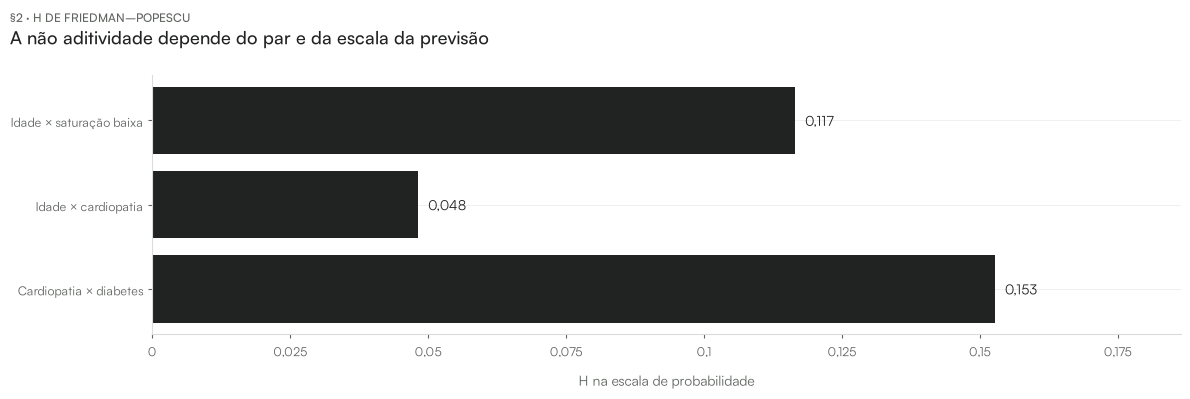

In [4]:
print(inspect.getsource(G.h_par))
pares = [
    ("idade_anos", "saturacao"),
    ("idade_anos", "cardiopati"),
    ("cardiopati", "diabetes"),
]
av = xp.iloc[:64]
resultados = {par: G.h_par(prever, xf, av, par) for par in pares}
resumo = pd.DataFrame(
    [
        {
            "par": " × ".join(par),
            **{k: r[k] for k in ["h", "h2", "numerador", "denominador"]},
        }
        for par, r in resultados.items()
    ]
)
print(
    "Pares avaliados:",
    SP.pt_int(len(pares)),
    "| pontos observados:",
    SP.pt_int(len(av)),
)
print(SP.tabela(resumo, casas=8))
fig, ax = plt.subplots(figsize=SP.FAIXA)
ax.barh(
    ["Idade × saturação baixa", "Idade × cardiopatia", "Cardiopatia × diabetes"],
    resumo["h"],
    color=SP.ESCURO,
)
ax.invert_yaxis()
ax.set_xlim(0, resumo["h"].max() * 1.22)
for i, h in enumerate(resumo["h"]):
    ax.annotate(
        SP.pt(h, 3),
        (h, i),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        color=SP.ESCURO,
        fontsize=10,
    )
ax.set(xlabel="H na escala de probabilidade")
SP.titulo(
    fig,
    "A não aditividade depende do par e da escala da previsão",
    "§2 · H de Friedman–Popescu",
)
SP.salvar(fig, "interaction-h")
plt.show()

**O que olhar.**

- Leia numerador e denominador junto do H; um denominador pequeno torna a razão sensível.
- H não mede importância nem causalidade; valores acima da unidade não são truncados pelo código.

## §3 — Ver onde a soma falha

Para idade e saturação, desenhamos a superfície marginal e retiramos os PDPs simples centralizados nos pontos observados. Este mapa é o resíduo usado para interpretar H; não é uma ANOVA ortogonal na distribuição conjunta.

Maior resíduo absoluto na grade, p.p.: 3,8895
figura: figures_generated/interaction-residuo.png


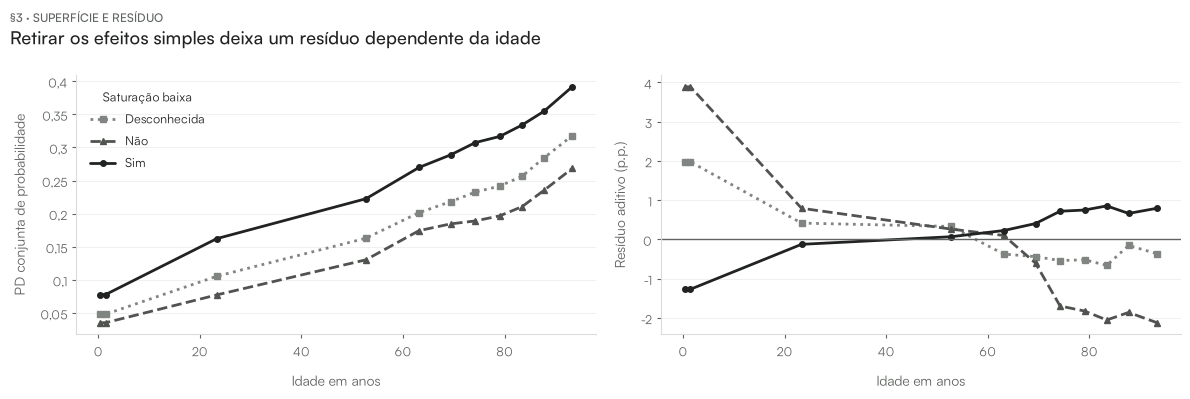

In [5]:
par = pares[0]
idades = np.unique(np.quantile(painel["idade_anos"], np.linspace(0.05, 0.95, 11)))
estados = list(xf["saturacao"].cat.categories)
pontos = pd.DataFrame(itertools.product(idades, estados), columns=list(par))
joint = G.pd_empirica(prever, xf, pontos).reshape(len(idades), len(estados))
one = G.pd_empirica(prever, xf, pd.DataFrame({par[0]: idades}))
two = G.pd_empirica(prever, xf, pd.DataFrame({par[1]: estados}))
# Mesmas constantes da definição de H nos pontos observados.
rawj = G.pd_empirica(prever, xf, av[[par[0]]]).mean()
rawk = G.pd_empirica(prever, xf, av[[par[1]]]).mean()
rawjk = G.pd_empirica(prever, xf, av[list(par)]).mean()
resid = joint - rawjk - (one - rawj)[:, None] - (two - rawk)[None, :]
print("Maior resíduo absoluto na grade, p.p.:", SP.pt(100 * np.abs(resid).max(), 4))
fig, axes = plt.subplots(1, 2, figsize=SP.FAIXA)
rotulos = {"desconhecido": "Desconhecida", "nao": "Não", "sim": "Sim"}
for k, estado in enumerate(estados):
    axes[0].plot(
        idades,
        joint[:, k],
        label=rotulos[estado],
        color=SP.rampa(len(estados), lo=0.5)[k],
        linestyle=[":", "--", "-"][k],
        marker=["s", "^", "o"][k],
        markersize=4,
    )
    axes[1].plot(
        idades,
        100 * resid[:, k],
        label=rotulos[estado],
        color=SP.rampa(len(estados), lo=0.5)[k],
        linestyle=[":", "--", "-"][k],
        marker=["s", "^", "o"][k],
        markersize=4,
    )
axes[0].set(xlabel="Idade em anos", ylabel="PD conjunta de probabilidade")
axes[1].set(xlabel="Idade em anos", ylabel="Resíduo aditivo (p.p.)")
axes[1].axhline(0, color=SP.CINZA, linewidth=1)
axes[0].legend(title="Saturação baixa")
SP.titulo(
    fig,
    "Retirar os efeitos simples deixa um resíduo dependente da idade",
    "§3 · Superfície e resíduo",
)
SP.salvar(fig, "interaction-residuo")
plt.show()

**O que olhar.**

- A magnitude do resíduo conserva unidades; H normaliza esse desvio por uma variação da superfície.
- O mapa usa uma grade para visualização, mas o H anterior usa os pares realmente observados.

## §4 — Trocar fundo e pontos pode alterar a razão

Mantemos o par e a receita. Alteramos o orçamento de integração e a semente do painel de pontos. A tabela é análise de sensibilidade, sem intervalo de confiança populacional.

In [6]:
sens = []
for seed, nf in [(42, 128), (42, 256), (43, 256)]:
    ev = M.design_matrix(teste.sample(n=64, random_state=seed))[0]
    rr = G.h_par(prever, xf.iloc[:nf], ev, pares[0])
    sens.append(
        {
            "semente dos pontos": seed,
            "fundo": nf,
            "pontos": len(ev),
            **{k: rr[k] for k in ["h", "h2", "denominador"]},
        }
    )
print(SP.tabela(pd.DataFrame(sens), casas=8))

semente dos pontos fundo pontos          h         h2 denominador
                42   128     64 0,11793297 0,01390818  0,00931979
                42   256     64 0,11656777 0,01358805  0,00958509
                43   256     64 0,12445226 0,01548836  0,01086422


**O que olhar.**

- Não confunda mudança de fundo e mudança de pontos com retreino: o modelo permanece fixo.
- A amostra hospitalizada e as correlações limitam a generalização da medida.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/interaction.html) orienta o mecanismo e a leitura. Interação é não aditividade numa escala declarada. H depende do fundo, dos pontos avaliados e de um denominador que precisa ser examinado. O caso SRAG acrescenta restrições do formulário, seleção hospitalar e deriva temporal. Nenhuma curva é uma estimativa do efeito de tratar ou modificar uma pessoa.

## §5 — Auditoria da base e da amostra de explicação

A referência é a amostra Gold commitada do projeto, não a extração bruta inteira do SIVEP-Gripe. Conferimos sua integridade e comparamos o painel com o teste temporal completo. As distribuições descritivas abaixo não demonstram representatividade populacional. O desfecho entra apenas nesta descrição posterior ao sorteio, nunca na construção das curvas.

O livro e o pacote foram inspecionados em revisões fixadas: [fonte do livro](https://github.com/christophM/interpretable-ml-book/tree/8f470c85e5ed4ebd69de74425cb9832f1bdc25eb) e [fonte de iml](https://github.com/giuseppec/iml/tree/4818c8f81dea2e76318857fbc3d50bc78cdd22f6). A avaliação distingue fórmula, configuração numérica, aplicação na base e alcance da interpretação. Não executamos o pacote R: as conferências de seu algoritmo são traduções explícitas para Python, identificadas nos internals.


In [7]:
from scipy.stats import ks_2samp

amostra_sha = hashlib.sha256(path.read_bytes()).hexdigest()
assert amostra_sha == "cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918"
assert gold["gold_id"].is_unique
assert not set(gold.loc[tr, "gold_id"]) & set(teste["gold_id"])
linhas = []
for nome, base in [("Teste temporal", teste), ("Painel", painel), ("Fundo", fundo)]:
    xx, _, yy = M.design_matrix(base)
    linhas.append(
        {
            "referência": nome,
            "fichas": len(base),
            "óbitos observados": int(yy.sum()),
            "fração óbito": yy.mean(),
            "previsão média": prever(xx).mean(),
            "idade p10": base["idade_anos"].quantile(0.1),
            "idade mediana": base["idade_anos"].median(),
            "idade p90": base["idade_anos"].quantile(0.9),
            "saturação sim": (base["saturacao"] == "sim").mean(),
            "saturação desconhecida": (base["saturacao"] == "desconhecido").mean(),
            "células ausentes em X": int(xx.isna().sum().sum()),
            "fora da coorte": int(M.gate_reasons(base)["fora_coorte"].sum()),
        }
    )
print(SP.tabela(pd.DataFrame(linhas), casas=6))
print("Identificadores únicos e treino/teste sem sobreposição:", True)
print(
    "Distância KS descritiva da idade, painel vs teste:",
    SP.pt(ks_2samp(painel["idade_anos"], teste["idade_anos"]).statistic, 6),
)
cat_p = painel["saturacao"].value_counts(normalize=True)
cat_t = teste["saturacao"].value_counts(normalize=True)
print(
    "Variação total da saturação, painel vs teste:",
    SP.pt(0.5 * (cat_p - cat_t).abs().sum(), 6),
)
print("Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb")
print("iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd22f6")
print("Execução nativa em R nesta auditoria:", False)

    referência fichas óbitos observados fração óbito previsão média idade p10 idade mediana idade p90 saturação sim saturação desconhecida células ausentes em X fora da coorte
Teste temporal 16.142             2.945     0,182443       0,215373  0,583436     68,555786 89,472961      0,616528               0,138397                     0              0
        Painel    512                94     0,183594       0,219387  0,760575     69,393570 90,069270      0,640625               0,134766                     0              0
         Fundo    256                51     0,199219       0,224372  0,947296     70,046539 90,754280      0,660156               0,140625                     0              0
Identificadores únicos e treino/teste sem sobreposição: True
Distância KS descritiva da idade, painel vs teste: 0,040275
Variação total da saturação, painel vs teste: 0,024097
Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb
iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd

## §6 — Sensibilidade com novos fundos e pontos observados

Repetimos a integração com fundos sorteados novamente e pontos avaliados por sementes distintas, mantendo o preditor e a escala. As amostras podem compartilhar fichas. As faixas observadas medem sensibilidade ao orçamento e ao sorteio; não são intervalos de confiança, nem validação de uma interação clínica. Todos os pares declarados são mantidos, sem seleção pelo resultado.


In [8]:
sens_audit = []
for seed in range(42, 47):
    bg = M.design_matrix(teste.sample(n=256, random_state=1000 + seed))[0]
    ev = M.design_matrix(teste.sample(n=128, random_state=2000 + seed))[0]
    for par in pares:
        rr = G.h_par(prever, bg, ev, par)
        sens_audit.append(
            {
                "semente": seed,
                "par": " × ".join(par),
                "fundo": len(bg),
                "pontos": len(ev),
                **{k: rr[k] for k in ["h", "h2", "numerador", "denominador"]},
            }
        )
sens_audit = pd.DataFrame(sens_audit)
print(SP.tabela(sens_audit, casas=8))
faixas_h = sens_audit.groupby("par", sort=False)["h"].agg(["min", "median", "max"])
print("Faixas descritivas de H em novos sorteios:")
print(SP.tabela(faixas_h.reset_index(), casas=8))
print(
    "Sorteios:",
    SP.pt_int(sens_audit["semente"].nunique()),
    "| fundo por sorteio:",
    SP.pt_int(256),
    "| pontos por sorteio:",
    SP.pt_int(128),
)

semente                     par fundo pontos          h         h2  numerador denominador
     42  idade_anos × saturacao   256    128 0,12470241 0,01555069 0,00019925  0,01281272
     42 idade_anos × cardiopati   256    128 0,04715419 0,00222352 0,00002560  0,01151141
     42   cardiopati × diabetes   256    128 0,15240359 0,02322686 0,00000049  0,00002102
     43  idade_anos × saturacao   256    128 0,12435263 0,01546358 0,00021304  0,01377695
     43 idade_anos × cardiopati   256    128 0,04864965 0,00236679 0,00002961  0,01251115
     43   cardiopati × diabetes   256    128 0,13258071 0,01757765 0,00000073  0,00004148
     44  idade_anos × saturacao   256    128 0,12256105 0,01502121 0,00018502  0,01231742
     44 idade_anos × cardiopati   256    128 0,05124301 0,00262585 0,00002766  0,01053448
     44   cardiopati × diabetes   256    128 0,13917007 0,01936831 0,00000066  0,00003405
     45  idade_anos × saturacao   256    128 0,13456697 0,01810827 0,00021257  0,01173873
     45 id

## Fechamento — A medida só faz sentido com seu condicionamento

Identifique preditor, escala, fundo, grade e regra de ponderação antes de interpretar a figura. Uma reconstrução algébrica ou um controle sintético valida o cálculo sob suas hipóteses; não valida as combinações artificiais como pacientes plausíveis.

In [9]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 21](https://christophm.github.io/interpretable-ml-book/interaction.html). Referências completas e configuração no [README](../README.md).